In [1]:
# ============================================================
# WEEK 14: EXTERNAL UNSEEN VIDEO TESTING
# CELL 1: SETUP AND DATASET FOLDERS
# ============================================================

import os
import torch
import pandas as pd

from pathlib import Path

# Project directories
ROOT = Path.cwd().parent
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

# External dataset directories
EXTERNAL_DIR = ROOT / "external_unseen_data"

REAL_DIR = EXTERNAL_DIR / "real"
FAKE_DIR = EXTERNAL_DIR / "deepfake"

# Create folders
REAL_DIR.mkdir(parents=True, exist_ok=True)
FAKE_DIR.mkdir(parents=True, exist_ok=True)

# Model checkpoint
CHECKPOINT_PATH = MODELS_DIR / "week4_resnet50.pth"

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("WEEK 14: EXTERNAL UNSEEN VIDEO TESTING")
print("=" * 55)

print("Project Root:", ROOT)
print("Device:", device)

print("\nCheckpoint Exists:", CHECKPOINT_PATH.exists())
print("External Dataset Folder:", EXTERNAL_DIR.exists())

print("\nReal Video Folder:", REAL_DIR)
print("Deepfake Video Folder:", FAKE_DIR)

# Count available videos
extensions = {".mp4", ".avi", ".mov", ".mkv"}

real_videos = [
    p for p in REAL_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

fake_videos = [
    p for p in FAKE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

print("\nReal Videos:", len(real_videos))
print("Deepfake Videos:", len(fake_videos))

print("\nWeek 14 Setup Completed!")

WEEK 14: EXTERNAL UNSEEN VIDEO TESTING
Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda

Checkpoint Exists: True
External Dataset Folder: True

Real Video Folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\external_unseen_data\real
Deepfake Video Folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\external_unseen_data\deepfake

Real Videos: 0
Deepfake Videos: 0

Week 14 Setup Completed!


In [2]:
# WEEK 14: CHECK IDENTICAL VIDEOS

import hashlib

def get_video_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


real_hashes = {
    get_video_hash(p): p.name
    for p in real_videos
}

fake_hashes = {
    get_video_hash(p): p.name
    for p in fake_videos
}

common_hashes = set(real_hashes) & set(fake_hashes)

print("IDENTICAL VIDEO CHECK")
print("=" * 45)

print("Real videos:", len(real_hashes))
print("Fake videos:", len(fake_hashes))
print("Identical files in both folders:", len(common_hashes))

for h in list(common_hashes)[:10]:
    print(
        "Real:", real_hashes[h],
        "| Fake:", fake_hashes[h]
    )

IDENTICAL VIDEO CHECK
Real videos: 0
Fake videos: 0
Identical files in both folders: 0


In [3]:
# WEEK 14: CHECK DATASET FOLDER STRUCTURE

print("REAL DIRECTORY")
print("Path:", REAL_DIR)
print("Exists:", REAL_DIR.exists())

print("\nREAL FOLDER CONTENTS:")
for p in list(REAL_DIR.rglob("*"))[:20]:
    print(p.relative_to(REAL_DIR), "| File:", p.is_file())

print("\nFAKE DIRECTORY")
print("Path:", FAKE_DIR)
print("Exists:", FAKE_DIR.exists())

print("\nFAKE FOLDER CONTENTS:")
for p in list(FAKE_DIR.rglob("*"))[:20]:
    print(p.relative_to(FAKE_DIR), "| File:", p.is_file())

REAL DIRECTORY
Path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\external_unseen_data\real
Exists: True

REAL FOLDER CONTENTS:
videos_fake | File: False
videos_fake\v1.mp4 | File: True
videos_fake\v10.mp4 | File: True
videos_fake\v11.mp4 | File: True
videos_fake\v12.mp4 | File: True
videos_fake\v13.mp4 | File: True
videos_fake\v14.mp4 | File: True
videos_fake\v15.mp4 | File: True
videos_fake\v16.mp4 | File: True
videos_fake\v17.mp4 | File: True
videos_fake\v18.mp4 | File: True
videos_fake\v19.mp4 | File: True
videos_fake\v2.mp4 | File: True
videos_fake\v20.mp4 | File: True
videos_fake\v21.mp4 | File: True
videos_fake\v22.mp4 | File: True
videos_fake\v23.mp4 | File: True
videos_fake\v24.mp4 | File: True
videos_fake\v25.mp4 | File: True
videos_fake\v26.mp4 | File: True

FAKE DIRECTORY
Path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\external_unseen_data\deepfake
Exists: True

FAKE FOLDER CONTENTS:
vs1.mp4 | File: True
vs10.mp4 | File: True
vs11.mp4 | File: True
v

In [4]:
print("REAL FOLDER")
for p in REAL_DIR.rglob("*.mp4"):
    print(p.relative_to(REAL_DIR))

print("\nDEEPFAKE FOLDER")
for p in FAKE_DIR.rglob("*.mp4"):
    print(p.relative_to(FAKE_DIR))

print("\nCOUNTS")
print("Real:", len(list(REAL_DIR.rglob("*.mp4"))))
print("Fake:", len(list(FAKE_DIR.rglob("*.mp4"))))

REAL FOLDER
videos_fake\v1.mp4
videos_fake\v10.mp4
videos_fake\v11.mp4
videos_fake\v12.mp4
videos_fake\v13.mp4
videos_fake\v14.mp4
videos_fake\v15.mp4
videos_fake\v16.mp4
videos_fake\v17.mp4
videos_fake\v18.mp4
videos_fake\v19.mp4
videos_fake\v2.mp4
videos_fake\v20.mp4
videos_fake\v21.mp4
videos_fake\v22.mp4
videos_fake\v23.mp4
videos_fake\v24.mp4
videos_fake\v25.mp4
videos_fake\v26.mp4
videos_fake\v27.mp4
videos_fake\v28.mp4
videos_fake\v29.mp4
videos_fake\v3.mp4
videos_fake\v30.mp4
videos_fake\v31.mp4
videos_fake\v32.mp4
videos_fake\v33.mp4
videos_fake\v34.mp4
videos_fake\v35.mp4
videos_fake\v36.mp4
videos_fake\v37.mp4
videos_fake\v38.mp4
videos_fake\v39.mp4
videos_fake\v4.mp4
videos_fake\v40.mp4
videos_fake\v41.mp4
videos_fake\v42.mp4
videos_fake\v43.mp4
videos_fake\v44.mp4
videos_fake\v45.mp4
videos_fake\v46.mp4
videos_fake\v47.mp4
videos_fake\v48.mp4
videos_fake\v49.mp4
videos_fake\v5.mp4
videos_fake\v50.mp4
videos_fake\v51.mp4
videos_fake\v52.mp4
videos_fake\v53.mp4
videos_fake\v

In [5]:
# Check video counts in every nested folder

for folder in [REAL_DIR, FAKE_DIR]:

    print("\nMAIN FOLDER:", folder.name)
    print("-" * 45)

    for subfolder in [folder] + [
        p for p in folder.rglob("*") if p.is_dir()
    ]:
        videos = [
            p for p in subfolder.iterdir()
            if p.is_file() and p.suffix.lower() in {
                ".mp4", ".avi", ".mov", ".mkv"
            }
        ]

        print(
            subfolder.relative_to(folder),
            ":", len(videos), "videos"
        )


MAIN FOLDER: real
---------------------------------------------
. : 0 videos
videos_fake : 53 videos

MAIN FOLDER: deepfake
---------------------------------------------
. : 53 videos


In [14]:
# Search for original videos_reals folder

print("SEARCHING FOR REAL VIDEOS")
print("=" * 45)

for p in ROOT.rglob("videos_reals"):
    if p.is_dir():
        count = sum(
            1 for f in p.rglob("*")
            if f.is_file() and f.suffix.lower() in
            {".mp4", ".avi", ".mov", ".mkv"}
        )

        print("Found:", p)
        print("Video count:", count)

SEARCHING FOR REAL VIDEOS


In [15]:
# Search for real dataset folder outside project root

SEARCH_DIR = ROOT.parent

print("Searching in:", SEARCH_DIR)
print("=" * 50)

for p in SEARCH_DIR.rglob("*"):
    if p.is_dir() and "real" in p.name.lower():
        videos = [
            f for f in p.rglob("*")
            if f.is_file() and f.suffix.lower()
            in {".mp4", ".avi", ".mov", ".mkv"}
        ]

        if videos:
            print("\nFolder:", p)
            print("Videos:", len(videos))

Searching in: c:\Users\HIMANSHU\Desktop\minor project 1

Folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\external_unseen_data\real
Videos: 53

Folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\Celeb-real
Videos: 590

Folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\YouTube-real
Videos: 300


In [16]:
import hashlib

def calculate_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


fake_inside_real = [
    p for p in REAL_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".mp4"
]

fake_inside_deepfake = [
    p for p in FAKE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".mp4"
]

hashes_real_folder = {
    calculate_hash(p) for p in fake_inside_real
}

hashes_fake_folder = {
    calculate_hash(p) for p in fake_inside_deepfake
}

print("Videos in real/videos_fake:", len(fake_inside_real))
print("Videos in deepfake:", len(fake_inside_deepfake))

print(
    "Identical videos:",
    len(hashes_real_folder & hashes_fake_folder)
)

Videos in real/videos_fake: 53
Videos in deepfake: 53
Identical videos: 0


In [22]:
# WEEK 14: EXTRACT VERIFIED SDFVD DATASET

import zipfile
import shutil
from pathlib import Path

VERIFIED_DIR = EXTERNAL_DIR / "verified"
VERIFIED_REAL_DIR = VERIFIED_DIR / "real"
VERIFIED_FAKE_DIR = VERIFIED_DIR / "deepfake"

VERIFIED_REAL_DIR.mkdir(parents=True, exist_ok=True)
VERIFIED_FAKE_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:

    for member in archive.namelist():

        normalized = member.replace("\\", "/")
        filename = Path(normalized).name

        if not filename.lower().endswith(".mp4"):
            continue

        if "/videos_real/" in normalized:
            destination = VERIFIED_REAL_DIR / filename

        elif "/videos_fake/" in normalized:
            destination = VERIFIED_FAKE_DIR / filename

        else:
            continue

        with archive.open(member) as source:
            with open(destination, "wb") as target:
                shutil.copyfileobj(source, target)

# Update dataset paths for all upcoming cells
REAL_DIR = VERIFIED_REAL_DIR
FAKE_DIR = VERIFIED_FAKE_DIR

real_videos = list(REAL_DIR.glob("*.mp4"))
fake_videos = list(FAKE_DIR.glob("*.mp4"))

print("REAL VIDEOS:", len(real_videos))
print("FAKE VIDEOS:", len(fake_videos))
print("TOTAL VIDEOS:", len(real_videos) + len(fake_videos))
print("Extraction completed!")

REAL VIDEOS: 53
FAKE VIDEOS: 53
TOTAL VIDEOS: 106
Extraction completed!


In [24]:
%pip install opencv-python

   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.0 MB ? eta -:--:--
    --------------------------------------- 0.8/48.0 MB 2.4 MB/s eta 0:00:20
   - -------------------------------------- 1.3/48.0 MB 2.5 MB/s eta 0:00:19
   - -------------------------------------- 2.1/48.0 MB 2.9 MB/s eta 0:00:16
   -- ------------------------------------- 3.1/48.0 MB 3.2 MB/s eta 0:00:14
   --- ------------------------------------ 3.9/48.0 MB 3.5 MB/s eta 0:00:13
   ---- ----------------------------------- 5.0/48.0 MB 3.7 MB/s eta 0:00:12
   ----- ---------------------------------- 6.3/48.0 MB 4.0 MB/s eta 0:00:11
   ------ --------------------------------- 7.6/48.0 MB 4.3 MB/s eta 0:00:10
   ------- -------------------------------- 8.9/48.0 MB 4.5 MB/s eta 0:00:09
   -------- ------------------------------- 10.5/48.0 MB 4.8 MB/s eta 0:00:08
   --------- ------------------------------ 11.5/48.0 MB 4.9 MB/s eta 0:00:08
   --------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
# WEEK 14: VERIFY EXTERNAL VIDEO FILES

import cv2
import pandas as pd

video_records = []

for label, folder in [
    (0, REAL_DIR),
    (1, FAKE_DIR)
]:
    for video_path in sorted(folder.glob("*.mp4")):

        cap = cv2.VideoCapture(str(video_path))

        is_opened = cap.isOpened()

        if is_opened:
            total_frames = int(
                cap.get(cv2.CAP_PROP_FRAME_COUNT)
            )
            fps = cap.get(cv2.CAP_PROP_FPS)
            width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

            ret, frame = cap.read()
            readable = ret and frame is not None
        else:
            total_frames = 0
            fps = 0
            width = 0
            height = 0
            readable = False

        cap.release()

        video_records.append({
            "video_path": str(video_path),
            "true_label": label,
            "total_frames": total_frames,
            "fps": fps,
            "width": width,
            "height": height,
            "readable": readable
        })

external_video_df = pd.DataFrame(video_records)

print("TOTAL VIDEOS:", len(external_video_df))
print("\nLABEL DISTRIBUTION:")
print(external_video_df["true_label"].value_counts())

print("\nREADABLE VIDEOS:")
print(external_video_df["readable"].value_counts())

print("\nVIDEO DETAILS:")
display(external_video_df.head())

external_video_df.to_csv(
    RESULTS_DIR / "week14_external_video_metadata.csv",
    index=False
)

TOTAL VIDEOS: 106

LABEL DISTRIBUTION:
true_label
0    53
1    53
Name: count, dtype: int64

READABLE VIDEOS:
readable
True    106
Name: count, dtype: int64

VIDEO DETAILS:


,video_path,true_label,total_frames,fps,width,height,readable
0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,81,30.0,1280,720,True
1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,109,30.0,378,720,True
2,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,81,30.0,1280,674,True
3,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,101,30.0,1280,720,True
4,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,80,30.0,1280,720,True


In [27]:
# CHECK OPENCV INSTALLATION

import cv2
import sys

print("Python:", sys.executable)
print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("OpenCV location:", cv2.__file__)

print("CascadeClassifier available:",
      hasattr(cv2, "CascadeClassifier"))

print("OpenCV data available:",
      hasattr(cv2, "data"))

Python: c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Scripts\python.exe
OpenCV version: 5.1.0
OpenCV location: c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Lib\site-packages\cv2\__init__.py
CascadeClassifier available: False
OpenCV data available: True


In [29]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.1.0.95
Uninstalling opencv-python-5.1.0.95:
  Successfully uninstalled opencv-python-5.1.0.95
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [30]:
%pip install opencv-contrib-python==4.10.0.84

   ---------------------------------------- 0.0/45.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/45.5 MB ? eta -:--:--
    --------------------------------------- 1.0/45.5 MB 3.0 MB/s eta 0:00:16
   - -------------------------------------- 1.8/45.5 MB 3.4 MB/s eta 0:00:14
   -- ------------------------------------- 2.9/45.5 MB 3.8 MB/s eta 0:00:12
   --- ------------------------------------ 3.9/45.5 MB 4.1 MB/s eta 0:00:11
   ---- ----------------------------------- 5.0/45.5 MB 4.3 MB/s eta 0:00:10
   ----- ---------------------------------- 5.8/45.5 MB 4.3 MB/s eta 0:00:10
   ------ --------------------------------- 7.3/45.5 MB 4.7 MB/s eta 0:00:09
   ------- -------------------------------- 8.4/45.5 MB 4.8 MB/s eta 0:00:08
   -------- ------------------------------- 9.4/45.5 MB 4.9 MB/s eta 0:00:08
   -------- ------------------------------- 10.0/45.5 MB 4.6 MB/s eta 0:00:08
   --------- ------------------------------ 10.7/45.5 MB 4.5 MB/s eta 0:00:08
   --------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import cv2

print("OpenCV:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

print("Cascade Loaded:", not face_detector.empty())

OpenCV: 4.10.0
CascadeClassifier: True
Cascade Loaded: True


In [3]:
from pathlib import Path
import torch
import cv2

# Project directories
ROOT = Path.cwd().parent
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

EXTERNAL_DIR = ROOT / "external_unseen_data"
VERIFIED_DIR = EXTERNAL_DIR / "verified"

REAL_DIR = VERIFIED_DIR / "real"
FAKE_DIR = VERIFIED_DIR / "deepfake"

CHECKPOINT_PATH = MODELS_DIR / "week4_resnet50.pth"

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Reload videos
real_videos = sorted(REAL_DIR.glob("*.mp4"))
fake_videos = sorted(FAKE_DIR.glob("*.mp4"))

print("Project Root:", ROOT)
print("Device:", device)
print("Checkpoint Exists:", CHECKPOINT_PATH.exists())
print("Real Videos:", len(real_videos))
print("Fake Videos:", len(fake_videos))
print("Total Videos:", len(real_videos) + len(fake_videos))
print("OpenCV:", cv2.__version__)

Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
Checkpoint Exists: True
Real Videos: 53
Fake Videos: 53
Total Videos: 106
OpenCV: 4.10.0


In [4]:
# RELOAD EXTERNAL VIDEO PATHS

from pathlib import Path

real_videos = sorted(REAL_DIR.glob("*.mp4"))
fake_videos = sorted(FAKE_DIR.glob("*.mp4"))

print("Real videos:", len(real_videos))
print("Fake videos:", len(fake_videos))
print("Total videos:", len(real_videos) + len(fake_videos))

Real videos: 53
Fake videos: 53
Total videos: 106


In [5]:
# WEEK 14: TEST FACE DETECTION ON EXTERNAL VIDEOS

import cv2
from pathlib import Path

cascade_path = (
    Path(cv2.data.haarcascades)
    / "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(str(cascade_path))

if face_detector.empty():
    raise RuntimeError("Haar Cascade failed to load!")

sample_videos = (
    real_videos[:3] + fake_videos[:2]
)

for video_path in sample_videos:

    cap = cv2.VideoCapture(str(video_path))

    total_faces = 0
    checked_frames = 0

    while checked_frames < 10:

        ret, frame = cap.read()

        if not ret:
            break

        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        faces = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(40, 40)
        )

        total_faces += len(faces)
        checked_frames += 1

    cap.release()

    print(
        video_path.name,
        "| Frames:", checked_frames,
        "| Detected faces:", total_faces
    )

v1.mp4 | Frames: 10 | Detected faces: 10
v10.mp4 | Frames: 10 | Detected faces: 10
v11.mp4 | Frames: 10 | Detected faces: 8
vs1.mp4 | Frames: 10 | Detected faces: 10
vs10.mp4 | Frames: 10 | Detected faces: 10


In [6]:
# WEEK 14: EXTERNAL DATASET FACE EXTRACTION

import cv2
import pandas as pd
from pathlib import Path

PROCESSED_DIR = EXTERNAL_DIR / "verified_faces"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

FACE_SIZE = 224
FRAMES_PER_VIDEO = 10

records = []

for label, folder in [(0, REAL_DIR), (1, FAKE_DIR)]:

    for video_path in sorted(folder.glob("*.mp4")):

        cap = cv2.VideoCapture(str(video_path))

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        # Select 10 evenly spaced frames
        frame_indices = sorted(set(
            int(x) for x in
            __import__("numpy").linspace(
                0, max(total_frames - 1, 0),
                FRAMES_PER_VIDEO
            )
        ))

        video_id = video_path.stem
        video_face_dir = PROCESSED_DIR / video_id
        video_face_dir.mkdir(parents=True, exist_ok=True)

        saved_faces = 0

        for frame_index in frame_indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
            ret, frame = cap.read()

            if not ret:
                continue

            gray = cv2.cvtColor(
                frame, cv2.COLOR_BGR2GRAY
            )

            faces = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(40, 40)
            )

            if len(faces) == 0:
                continue

            # Select largest detected face
            x, y, w, h = max(
                faces,
                key=lambda box: box[2] * box[3]
            )

            face = frame[y:y+h, x:x+w]

            face = cv2.resize(
                face, (FACE_SIZE, FACE_SIZE)
            )

            face_path = (
                video_face_dir /
                f"{video_id}_frame_{frame_index}.jpg"
            )

            cv2.imwrite(str(face_path), face)

            records.append({
                "video_path": str(video_path),
                "video_id": video_id,
                "face_path": str(face_path),
                "label": label,
                "frame_index": frame_index
            })

            saved_faces += 1

        cap.release()

        print(
            video_path.name,
            "| Label:", label,
            "| Faces:", saved_faces
        )

external_face_df = pd.DataFrame(records)

external_face_df.to_csv(
    RESULTS_DIR / "week14_external_face_metadata.csv",
    index=False
)

print("\nEXTRACTION SUMMARY")
print("Total videos:", len(real_videos) + len(fake_videos))
print("Total faces extracted:", len(external_face_df))
print("\nLabel distribution:")
print(external_face_df["label"].value_counts())
print("\nMetadata saved successfully!")

v1.mp4 | Label: 0 | Faces: 10
v10.mp4 | Label: 0 | Faces: 10
v11.mp4 | Label: 0 | Faces: 3
v12.mp4 | Label: 0 | Faces: 9
v13.mp4 | Label: 0 | Faces: 10
v14.mp4 | Label: 0 | Faces: 10
v15.mp4 | Label: 0 | Faces: 10
v16.mp4 | Label: 0 | Faces: 10
v17.mp4 | Label: 0 | Faces: 10
v18.mp4 | Label: 0 | Faces: 10
v19.mp4 | Label: 0 | Faces: 6
v2.mp4 | Label: 0 | Faces: 10
v20.mp4 | Label: 0 | Faces: 4
v21.mp4 | Label: 0 | Faces: 10
v22.mp4 | Label: 0 | Faces: 10
v23.mp4 | Label: 0 | Faces: 10
v24.mp4 | Label: 0 | Faces: 10
v25.mp4 | Label: 0 | Faces: 10
v26.mp4 | Label: 0 | Faces: 10
v27.mp4 | Label: 0 | Faces: 10
v28.mp4 | Label: 0 | Faces: 10
v29.mp4 | Label: 0 | Faces: 10
v3.mp4 | Label: 0 | Faces: 10
v30.mp4 | Label: 0 | Faces: 10
v31.mp4 | Label: 0 | Faces: 10
v32.mp4 | Label: 0 | Faces: 10
v33.mp4 | Label: 0 | Faces: 1
v34.mp4 | Label: 0 | Faces: 9
v35.mp4 | Label: 0 | Faces: 9
v36.mp4 | Label: 0 | Faces: 10
v37.mp4 | Label: 0 | Faces: 10
v38.mp4 | Label: 0 | Faces: 10
v39.mp4 | Label: 0

In [7]:
# WEEK 14: VERIFY EXTRACTED FACE DATASET

import pandas as pd

metadata_path = (
    RESULTS_DIR / "week14_external_face_metadata.csv"
)

external_face_df = pd.read_csv(metadata_path)

print("TOTAL EXTRACTED FACES:", len(external_face_df))

print("\nLABEL-WISE FACE COUNT:")
print(external_face_df["label"].value_counts().sort_index())

print("\nUNIQUE VIDEOS:")
print(external_face_df.groupby("label")["video_id"].nunique())

print("\nFACES PER VIDEO:")
face_counts = external_face_df.groupby(
    ["label", "video_id"]
).size()

print(face_counts.groupby(level=0).describe())

print("\nMISSING FACE FILES:")
missing = sum(
    not Path(p).exists()
    for p in external_face_df["face_path"]
)

print(missing)

print("\nMETADATA SHAPE:", external_face_df.shape)

TOTAL EXTRACTED FACES: 941

LABEL-WISE FACE COUNT:
label
0    465
1    476
Name: count, dtype: int64

UNIQUE VIDEOS:
label
0    53
1    53
Name: video_id, dtype: int64

FACES PER VIDEO:
       count      mean       std  min  25%   50%   75%   max
label                                                       
0       53.0  8.773585  2.485663  1.0  9.0  10.0  10.0  10.0
1       53.0  8.981132  1.995096  3.0  9.0  10.0  10.0  10.0

MISSING FACE FILES:
0

METADATA SHAPE: (941, 5)


In [8]:
# WEEK 14: INSPECT RESNET50 CHECKPOINT

import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    print("\nFirst 15 weight keys:")
    print(list(state_dict.keys())[:15])

    print("\nFinal layer weight shape:")
    print(state_dict["fc.weight"].shape)

else:
    print("Checkpoint is not a dictionary.")

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.0.conv3.weight', 'layer1.0.bn3.weight', 'layer1.0.bn3.bias', 'layer1.0.bn3.running_mean', 'layer1.0.bn3.running_var', 'layer1.0.bn3.num_batches_tracked', 'layer1.0.downsample.0.weight', 'layer1.0.downsample.1.weight', 'layer1.0.downsample.1.bias', 'layer1.0.downsample.1.running_mean', 'layer1.0.downsample.1.running_var', 'layer1.0.downsample.1.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_va

In [10]:
# WEEK 14: LOAD TRAINED RESNET50 MODEL

import torch
import torch.nn as nn
from torchvision import models

# Load ResNet50 architecture
model = models.resnet50(weights=None)

# Binary classification output
model.fc = nn.Linear(
    model.fc.in_features,
    1
)

# Load trained weights
state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("ResNet50 loaded successfully!")
print("Device:", device)
print("Model parameters:", sum(
    p.numel() for p in model.parameters()
))
print("Checkpoint:", CHECKPOINT_PATH)

ResNet50 loaded successfully!
Device: cuda
Model parameters: 23510081
Checkpoint: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\models\week4_resnet50.pth


In [11]:
# WEEK 14: RESNET50 EXTERNAL FACE-LEVEL PREDICTIONS

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Same normalization used during ResNet50 training
external_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ExternalFaceDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(
            row["face_path"]
        ).convert("RGB")

        image = self.transform(image)

        return image, int(row["label"])


external_dataset = ExternalFaceDataset(
    external_face_df,
    external_transform
)

external_loader = DataLoader(
    external_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

all_probabilities = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in external_loader:

        images = images.to(device)

        outputs = model(images).squeeze(1)

        probabilities = torch.sigmoid(outputs)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_labels.extend(labels.numpy())

# Save face-level predictions
external_face_predictions = external_face_df.copy()

external_face_predictions["probability_fake"] = all_probabilities

THRESHOLD = 0.14

external_face_predictions["predicted_label"] = (
    external_face_predictions["probability_fake"]
    >= THRESHOLD
).astype(int)

external_face_predictions.to_csv(
    RESULTS_DIR / "week14_external_face_predictions.csv",
    index=False
)

print("Face predictions completed!")
print("Total face crops:", len(external_face_predictions))
print("Threshold:", THRESHOLD)

print("\nPrediction distribution:")
print(
    external_face_predictions["predicted_label"]
    .value_counts().sort_index()
)

print("\nSample predictions:")
display(external_face_predictions.head(10))

Face predictions completed!
Total face crops: 941
Threshold: 0.14

Prediction distribution:
predicted_label
0    753
1    188
Name: count, dtype: int64

Sample predictions:


,video_path,video_id,face_path,label,frame_index,probability_fake,predicted_label
0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,0,0.125636,0
1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,8,0.147463,1
2,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,17,0.087658,0
3,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,26,0.502801,1
4,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,35,0.348097,1
5,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,44,0.131100,0
6,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,53,0.415624,1
7,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,62,0.139623,0
8,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,71,0.300175,1
9,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,v1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,0,80,0.082157,0


In [12]:
# WEEK 14: VIDEO-LEVEL EXTERNAL EVALUATION

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Aggregate face predictions into video predictions
external_video_predictions = (
    external_face_predictions
    .groupby(["video_path", "video_id"], as_index=False)
    .agg(
        true_label=("label", "first"),
        probability_fake=("probability_fake", "mean"),
        face_count=("label", "count")
    )
)

# Apply the same threshold used in Week 8
external_video_predictions["predicted_label"] = (
    external_video_predictions["probability_fake"]
    >= THRESHOLD
).astype(int)

y_true = external_video_predictions["true_label"]
y_pred = external_video_predictions["predicted_label"]
y_prob = external_video_predictions["probability_fake"]

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

print("=" * 55)
print("SDFVD EXTERNAL VIDEO-LEVEL EVALUATION")
print("=" * 55)

print("Total Videos:", len(external_video_predictions))
print("Threshold:", THRESHOLD)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nCONFUSION MATRIX:")
cm = confusion_matrix(y_true, y_pred)
print(cm)

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Real", "Deepfake"],
        zero_division=0
    )
)

# Save video-level predictions
external_video_predictions.to_csv(
    RESULTS_DIR / "week14_external_video_predictions.csv",
    index=False
)

# Save metrics
external_metrics = pd.DataFrame([{
    "dataset": "SDFVD",
    "total_videos": len(external_video_predictions),
    "threshold": THRESHOLD,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc
}])

external_metrics.to_csv(
    RESULTS_DIR / "week14_external_evaluation_metrics.csv",
    index=False
)

print("\nResults saved successfully!")

SDFVD EXTERNAL VIDEO-LEVEL EVALUATION
Total Videos: 106
Threshold: 0.14
Accuracy: 0.4434
Precision: 0.3846
Recall: 0.1887
F1-Score: 0.2532
ROC-AUC: 0.4158

CONFUSION MATRIX:
[[37 16]
 [43 10]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Real       0.46      0.70      0.56        53
    Deepfake       0.38      0.19      0.25        53

    accuracy                           0.44       106
   macro avg       0.42      0.44      0.40       106
weighted avg       0.42      0.44      0.40       106


Results saved successfully!


In [13]:
# WEEK 14: EXTERNAL PREDICTION CONFIDENCE ANALYSIS

confidence_summary = (
    external_video_predictions
    .groupby("true_label")["probability_fake"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

confidence_summary.index = ["Real", "Deepfake"]

print("EXTERNAL CONFIDENCE SUMMARY")
display(confidence_summary)

print("\nPREDICTION DISTRIBUTION:")
print(
    external_video_predictions
    .groupby(["true_label", "predicted_label"])
    .size()
    .unstack(fill_value=0)
)

confidence_summary.to_csv(
    RESULTS_DIR / "week14_external_confidence_analysis.csv"
)

print("\nConfidence analysis saved!")

EXTERNAL CONFIDENCE SUMMARY


,count,mean,std,min,median,max
Real,53,0.128089,0.186715,1.222010e-07,0.031144,0.877938
Deepfake,53,0.091543,0.177098,3.401380e-07,0.014262,0.788746



PREDICTION DISTRIBUTION:
predicted_label   0   1
true_label             
0                37  16
1                43  10

Confidence analysis saved!


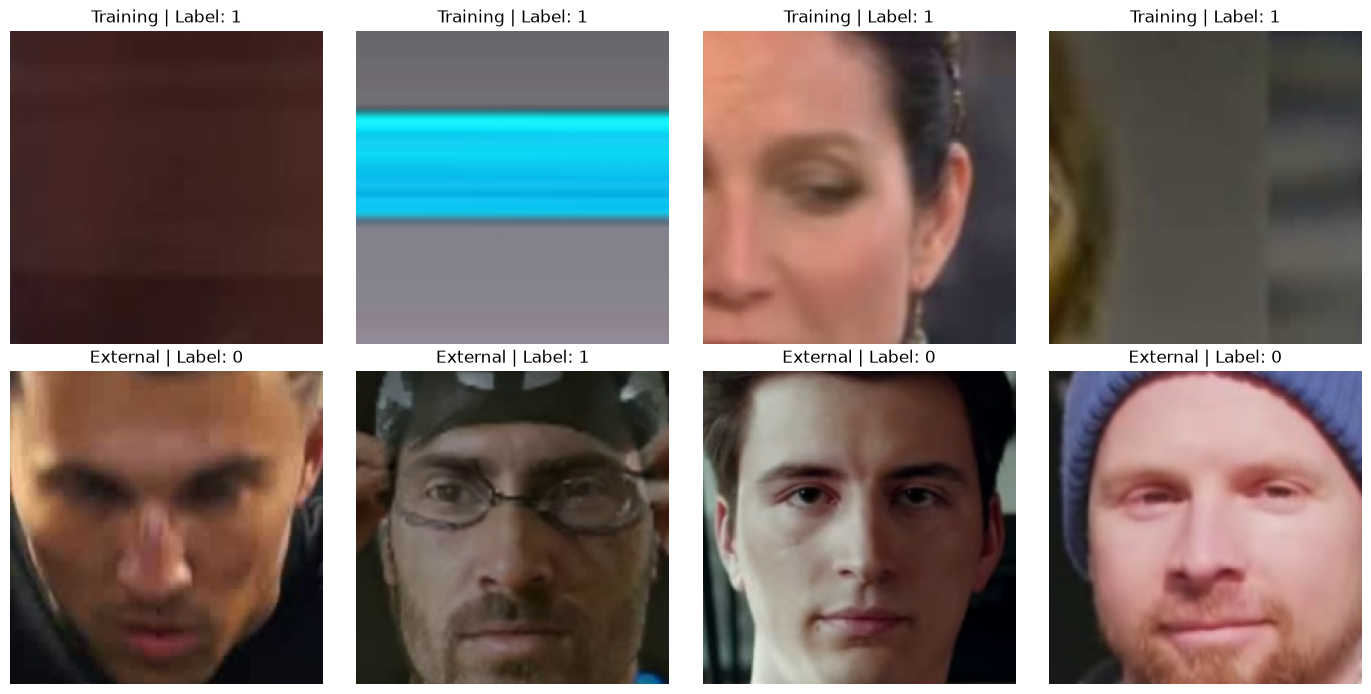

In [14]:
# ============================================================
# WEEK 14: TRAINING VS EXTERNAL FACE IMAGE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Load training metadata
train_metadata = pd.read_csv(
    RESULTS_DIR / "final_face_metadata.csv"
)

# Load external metadata
external_metadata = pd.read_csv(
    RESULTS_DIR / "week14_external_face_metadata.csv"
)

# Select sample images
train_sample = train_metadata.sample(
    n=4,
    random_state=42
)

external_sample = external_metadata.sample(
    n=4,
    random_state=42
)

# Display training images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, (_, row) in enumerate(train_sample.iterrows()):
    image_path = Path(row["face_path"])

    if not image_path.exists():
        image_path = ROOT / image_path

    image = Image.open(image_path).convert("RGB")

    axes[0, i].imshow(image)
    axes[0, i].set_title(
        f"Training | Label: {row['label']}"
    )
    axes[0, i].axis("off")

# Display external images
for i, (_, row) in enumerate(external_sample.iterrows()):
    image_path = Path(row["face_path"])

    if not image_path.exists():
        image_path = ROOT / image_path

    image = Image.open(image_path).convert("RGB")

    axes[1, i].imshow(image)
    axes[1, i].set_title(
        f"External | Label: {row['label']}"
    )
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

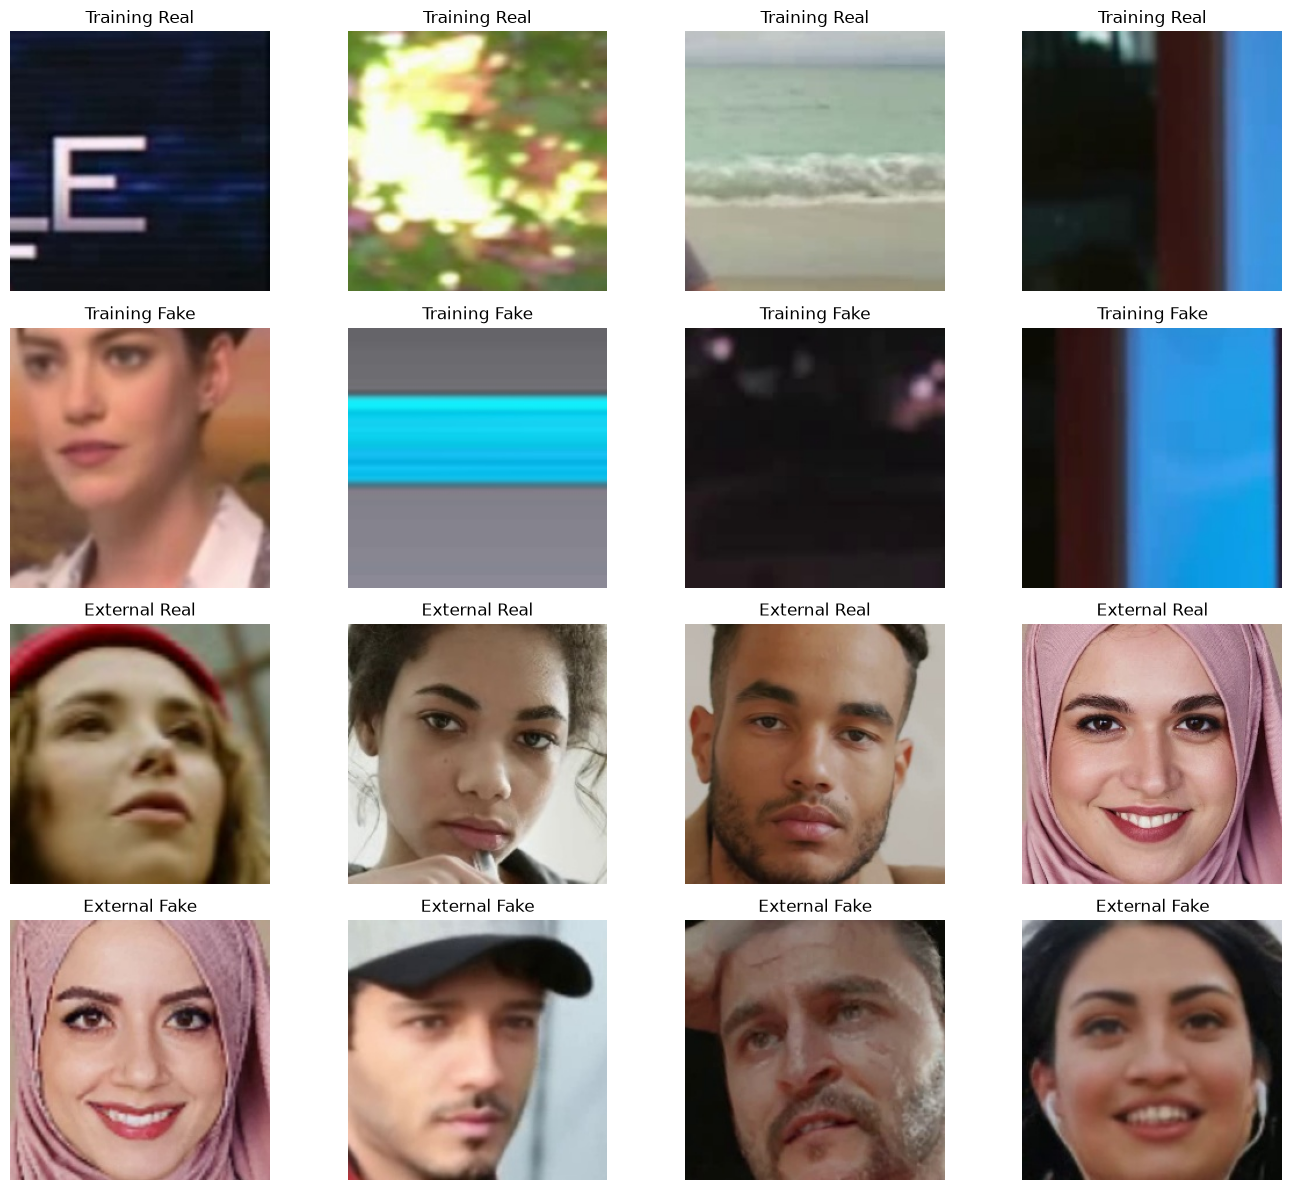

In [15]:
# ============================================================
# WEEK 14: BALANCED FACE CROP QUALITY INSPECTION
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

def resolve_image_path(path):
    path = Path(str(path))

    candidates = [
        path,
        ROOT / path
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


# Select balanced samples from all four groups
groups = [
    ("Training Real", train_metadata[train_metadata["label"] == 0]),
    ("Training Fake", train_metadata[train_metadata["label"] == 1]),
    ("External Real", external_metadata[external_metadata["label"] == 0]),
    ("External Fake", external_metadata[external_metadata["label"] == 1])
]

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for row, (group_name, group_df) in enumerate(groups):

    samples = group_df.sample(
        n=min(4, len(group_df)),
        random_state=42
    )

    for col in range(4):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(samples):
            continue

        image_path = resolve_image_path(
            samples.iloc[col]["face_path"]
        )

        if image_path is None:
            ax.set_title("Image Missing")
            continue

        try:
            image = Image.open(image_path).convert("RGB")
            ax.imshow(image)
            ax.set_title(group_name)
        except Exception as e:
            ax.set_title("Image Error")

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# WEEK 14: FACE CROP QUALITY AUDIT
# ============================================================

import cv2
import pandas as pd
from pathlib import Path

# Load Haar Cascade
cascade_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(cascade_path)

# Four dataset groups
groups = {
    "Training Real": train_metadata[
        train_metadata["label"] == 0
    ],
    "Training Fake": train_metadata[
        train_metadata["label"] == 1
    ],
    "External Real": external_metadata[
        external_metadata["label"] == 0
    ],
    "External Fake": external_metadata[
        external_metadata["label"] == 1
    ]
}

audit_results = []

for group_name, group_df in groups.items():

    # Randomly inspect up to 200 images per group
    sample_df = group_df.sample(
        n=min(200, len(group_df)),
        random_state=42
    )

    detected = 0
    missing = 0

    for _, row in sample_df.iterrows():

        image_path = resolve_image_path(row["face_path"])

        if image_path is None:
            missing += 1
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            missing += 1
            continue

        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2GRAY
        )

        faces = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        if len(faces) > 0:
            detected += 1

    checked = len(sample_df) - missing

    audit_results.append({
        "Dataset": group_name,
        "Sampled": len(sample_df),
        "Checked": checked,
        "Face_Detected": detected,
        "No_Face_Detected": checked - detected,
        "Missing_or_Invalid": missing,
        "Detection_Percentage": (
            detected / checked * 100 if checked else 0
        )
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df.round(2))

audit_df.to_csv(
    RESULTS_DIR / "week14_face_quality_audit.csv",
    index=False
)

print("Face quality audit saved!")

,Dataset,Sampled,Checked,Face_Detected,No_Face_Detected,Missing_or_Invalid,Detection_Percentage
0,Training Real,200,200,8,192,0,4.0
1,Training Fake,200,200,12,188,0,6.0
2,External Real,200,200,171,29,0,85.5
3,External Fake,200,200,173,27,0,86.5


Face quality audit saved!


In [17]:
# ============================================================
# WEEK 14: TRAINING IMAGE PATH VERIFICATION
# ============================================================

for class_name, label in [("REAL", 0), ("DEEPFAKE", 1)]:

    print(f"\n{'='*55}")
    print(f"TRAINING {class_name} SAMPLES")
    print("="*55)

    samples = train_metadata[
        train_metadata["label"] == label
    ].sample(n=5, random_state=42)

    for _, row in samples.iterrows():

        image_path = resolve_image_path(row["face_path"])

        print("\nFace path:", row["face_path"])
        print("Resolved path:", image_path)
        print("File exists:", image_path is not None)

        if image_path is not None:
            with Image.open(image_path) as img:
                print("Image size:", img.size)
                print("Image mode:", img.mode)

        print("Original video:", row["video_path"])

print("\nPath verification completed!")


TRAINING REAL SAMPLES

Face path: results\processed_faces\real\id25_0007_face_06.jpg
Resolved path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id25_0007_face_06.jpg
File exists: True
Image size: (224, 224)
Image mode: RGB
Original video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id25_0007.mp4

Face path: results\processed_faces\real\id2_0007_face_09.jpg
Resolved path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id2_0007_face_09.jpg
File exists: True
Image size: (224, 224)
Image mode: RGB
Original video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id2_0007.mp4

Face path: results\processed_faces\real\00241_face_02.jpg
Resolved path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\00241_face_02.jpg
File exists: True
Image size: (224, 224)
Image mode: RGB
Original video: c:\Users

In [18]:
# ============================================================
# WEEK 14: ORIGINAL TRAINING VIDEO PATH VERIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

sample_rows = []

for class_name, label in [
    ("Training Real", 0),
    ("Training Fake", 1)
]:

    samples = train_metadata[
        train_metadata["label"] == label
    ].sample(n=10, random_state=42)

    for _, row in samples.iterrows():

        video_path = Path(str(row["video_path"]))
        face_path = resolve_image_path(row["face_path"])

        sample_rows.append({
            "Class": class_name,
            "Video_Path": str(video_path),
            "Video_Exists": video_path.exists(),
            "Face_Image_Exists": face_path is not None,
            "Video_Name": video_path.name
        })

path_check_df = pd.DataFrame(sample_rows)

display(path_check_df)

print("\nVIDEO PATH SUMMARY")
print(
    path_check_df.groupby("Class")["Video_Exists"]
    .value_counts()
)

print("\nFACE IMAGE SUMMARY")
print(
    path_check_df.groupby("Class")["Face_Image_Exists"]
    .value_counts()
)

,Class,Video_Path,Video_Exists,Face_Image_Exists,Video_Name
0,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id25_0007.mp4
1,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id2_0007.mp4
2,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,00241.mp4
3,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id38_0000.mp4
4,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,00097.mp4
5,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id52_0009.mp4
6,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id5_0004.mp4
7,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id0_0008.mp4
8,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,00109.mp4
9,Training Real,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,False,True,id11_0005.mp4



VIDEO PATH SUMMARY
Class          Video_Exists
Training Fake  False           10
Training Real  False           10
Name: count, dtype: int64

FACE IMAGE SUMMARY
Class          Face_Image_Exists
Training Fake  True                 10
Training Real  True                 10
Name: count, dtype: int64


In [19]:
# ============================================================
# CHECK ORIGINAL CELEB-DF-V2 DATASET LOCATION
# ============================================================

from pathlib import Path

possible_paths = [
    ROOT / "datasets" / "Celeb-DF-v2",
    ROOT / "dataset" / "Celeb-DF-v2",
    ROOT / "Celeb-DF-v2",
]

for dataset_path in possible_paths:

    print("\nDataset path:", dataset_path)
    print("Exists:", dataset_path.exists())

    if dataset_path.exists():

        for folder_name in [
            "Celeb-real",
            "Celeb-synthesis",
            "YouTube-real"
        ]:
            folder = dataset_path / folder_name

            if folder.exists():
                videos = list(folder.glob("*.mp4"))
                print(folder_name, ":", len(videos), "videos")
            else:
                print(folder_name, ": NOT FOUND")


Dataset path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2
Exists: True
Celeb-real : 590 videos
Celeb-synthesis : 5639 videos
YouTube-real : 300 videos

Dataset path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\dataset\Celeb-DF-v2
Exists: False

Dataset path: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\Celeb-DF-v2
Exists: False


In [20]:
# ============================================================
# WEEK 14: REPAIR AND VERIFY ORIGINAL VIDEO PATHS
# ============================================================

from pathlib import Path
import pandas as pd

DATASET_DIR = ROOT / "datasets" / "Celeb-DF-v2"

REAL_DIRS = [
    DATASET_DIR / "Celeb-real",
    DATASET_DIR / "YouTube-real"
]

FAKE_DIR = DATASET_DIR / "Celeb-synthesis"

# Build video filename lookup
video_lookup = {}

for folder in REAL_DIRS + [FAKE_DIR]:
    for video in folder.rglob("*.mp4"):
        video_lookup.setdefault(video.name, []).append(video)

# Get unique videos from training metadata
unique_videos = train_metadata[
    ["video_path", "label"]
].drop_duplicates()

verified_paths = []
missing_videos = []
ambiguous_videos = []

for _, row in unique_videos.iterrows():

    filename = Path(str(row["video_path"])).name
    label = int(row["label"])

    candidates = video_lookup.get(filename, [])

    # Match class with correct source folder
    if label == 0:
        candidates = [
            p for p in candidates
            if p.parent.name in ["Celeb-real", "YouTube-real"]
        ]
    else:
        candidates = [
            p for p in candidates
            if p.parent.name == "Celeb-synthesis"
        ]

    if len(candidates) == 1:
        verified_paths.append({
            "video_name": filename,
            "label": label,
            "correct_video_path": str(candidates[0])
        })

    elif len(candidates) == 0:
        missing_videos.append(filename)

    else:
        ambiguous_videos.append({
            "video_name": filename,
            "matches": [str(p) for p in candidates]
        })

verified_df = pd.DataFrame(verified_paths)

print("VIDEO PATH VERIFICATION")
print("=" * 45)
print("Unique metadata videos:", len(unique_videos))
print("Successfully matched:", len(verified_df))
print("Missing videos:", len(missing_videos))
print("Ambiguous videos:", len(ambiguous_videos))

print("\nSAMPLE VERIFIED PATHS:")
display(verified_df.head(10))

print("\nMISSING VIDEO EXAMPLES:")
print(missing_videos[:10])

print("\nAMBIGUOUS VIDEO EXAMPLES:")
print(ambiguous_videos[:5])

VIDEO PATH VERIFICATION
Unique metadata videos: 6165
Successfully matched: 6165
Missing videos: 0
Ambiguous videos: 0

SAMPLE VERIFIED PATHS:


,video_name,label,correct_video_path
0,id0_0000.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
1,id0_0001.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
2,id0_0002.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
3,id0_0003.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
4,id0_0004.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
5,id0_0005.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
6,id0_0006.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
7,id0_0007.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
8,id0_0008.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...
9,id0_0009.mp4,0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...



MISSING VIDEO EXAMPLES:
[]

AMBIGUOUS VIDEO EXAMPLES:
[]


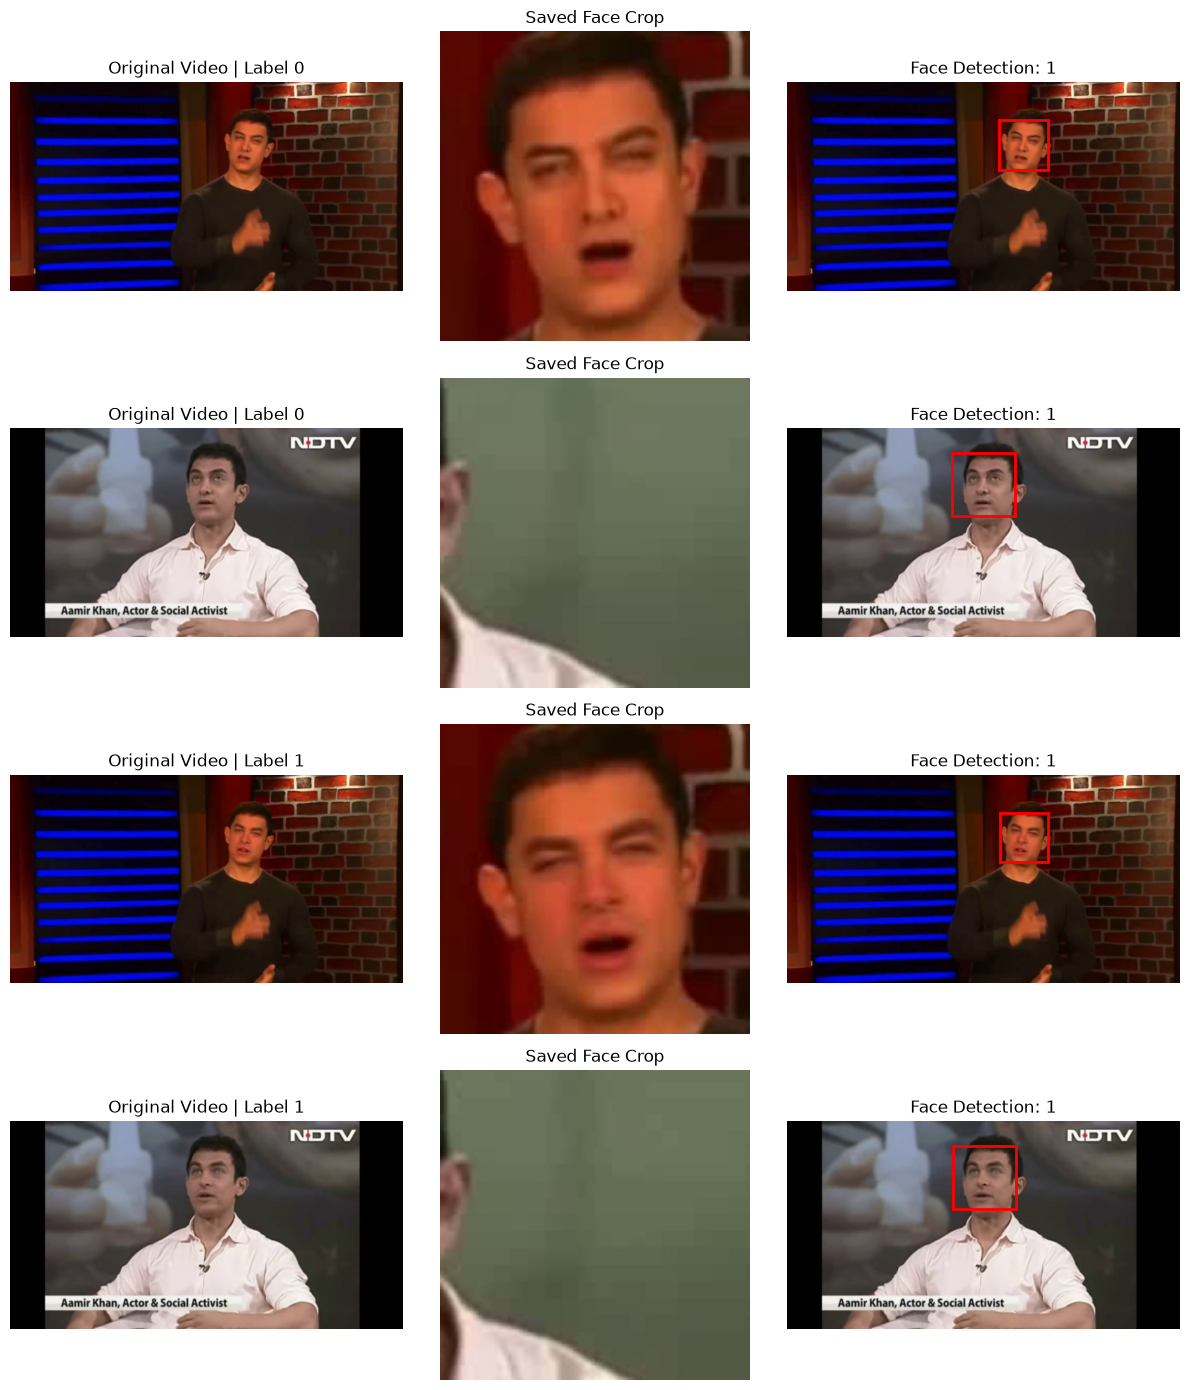

In [21]:
# ============================================================
# WEEK 14: ORIGINAL VIDEO VS EXTRACTED FACE CROP
# ============================================================

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Select 2 videos from each class
selected = verified_df.groupby("label").head(2)

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row_idx, (_, row) in enumerate(selected.iterrows()):

    video_path = Path(row["correct_video_path"])

    # Find one saved crop for this video
    matching_crops = train_metadata[
        train_metadata["video_path"].apply(
            lambda x: Path(str(x)).name == row["video_name"]
        )
    ]

    crop_path = resolve_image_path(
        matching_crops.iloc[0]["face_path"]
    )

    # Read original video
    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    middle_frame = max(0, total_frames // 2)

    cap.set(cv2.CAP_PROP_POS_FRAMES, middle_frame)
    success, frame = cap.read()
    cap.release()

    # Display original frame
    if success:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[row_idx, 0].imshow(frame)
        axes[row_idx, 0].set_title(
            f"Original Video | Label {row['label']}"
        )
    else:
        axes[row_idx, 0].set_title("Frame Read Failed")

    # Display saved face crop
    if crop_path is not None:
        crop = Image.open(crop_path).convert("RGB")
        axes[row_idx, 1].imshow(crop)
        axes[row_idx, 1].set_title("Saved Face Crop")
    else:
        axes[row_idx, 1].set_title("Crop Missing")

    # Display detected faces in original frame
    if success:
        gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)

        faces = face_detector.detectMultiScale(
            gray, 1.1, 5, minSize=(40, 40)
        )

        axes[row_idx, 2].imshow(frame)

        for (x, y, w, h) in faces:
            axes[row_idx, 2].add_patch(
                plt.Rectangle(
                    (x, y), w, h,
                    fill=False, edgecolor="red", linewidth=2
                )
            )

        axes[row_idx, 2].set_title(
            f"Face Detection: {len(faces)}"
        )

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()


Video: id0_0000.mp4 | Label: 0
Matching crops: 10

Video: id0_0001.mp4 | Label: 0
Matching crops: 10

Video: id0_id16_0000.mp4 | Label: 1
Matching crops: 10

Video: id0_id16_0001.mp4 | Label: 1
Matching crops: 10


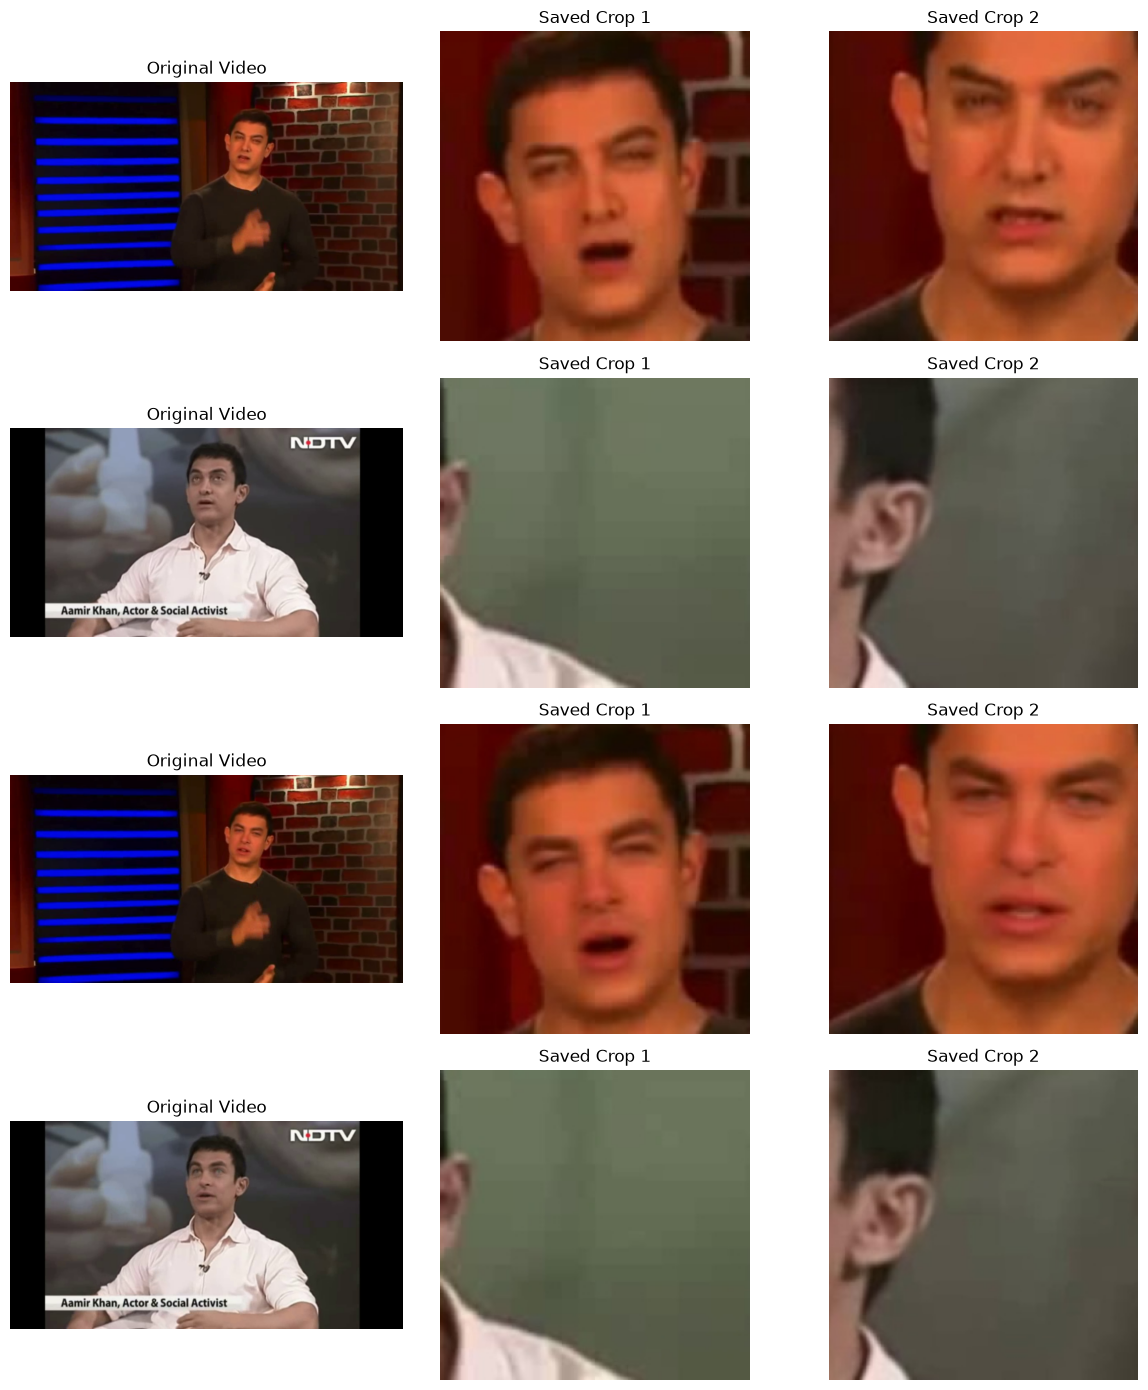

In [22]:
# ============================================================
# WEEK 14: CORRECT VIDEO-TO-FACE CROP MATCHING
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

selected = verified_df.groupby("label").head(2)

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row_idx, (_, row) in enumerate(selected.iterrows()):

    video_name = row["video_name"]
    label = int(row["label"])

    # Match using BOTH filename and label
    matching_crops = train_metadata[
        (train_metadata["video_path"].apply(
            lambda x: Path(str(x)).name == video_name
        ))
        &
        (train_metadata["label"] == label)
    ]

    print(
        f"\nVideo: {video_name} | Label: {label}"
    )
    print("Matching crops:", len(matching_crops))

    # Show original video frame
    video_path = Path(row["correct_video_path"])
    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        max(0, total_frames // 2)
    )

    success, frame = cap.read()
    cap.release()

    if success:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[row_idx, 0].imshow(frame)
        axes[row_idx, 0].set_title("Original Video")
    else:
        axes[row_idx, 0].set_title("Frame Read Failed")

    # Show first and last saved crops for this exact video/class
    if len(matching_crops) > 0:

        crop_rows = matching_crops.iloc[
            [0, -1]
        ] if len(matching_crops) > 1 else matching_crops

        for col, (_, crop_row) in enumerate(
            crop_rows.iterrows(), start=1
        ):
            crop_path = resolve_image_path(
                crop_row["face_path"]
            )

            if crop_path:
                img = Image.open(crop_path).convert("RGB")
                axes[row_idx, col].imshow(img)
                axes[row_idx, col].set_title(
                    f"Saved Crop {col}"
                )
            else:
                axes[row_idx, col].set_title("Missing Crop")

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# WEEK 14: DUPLICATE TRAINING FACE IMAGE AUDIT
# ============================================================

import hashlib
from collections import defaultdict
from pathlib import Path
import pandas as pd

hash_groups = defaultdict(list)

for _, row in train_metadata.iterrows():

    image_path = resolve_image_path(row["face_path"])

    if image_path is None:
        continue

    with open(image_path, "rb") as f:
        image_hash = hashlib.md5(f.read()).hexdigest()

    hash_groups[image_hash].append({
        "video_name": Path(
            str(row["video_path"])
        ).name,
        "label": int(row["label"]),
        "face_path": str(row["face_path"])
    })

duplicates = []

for image_hash, entries in hash_groups.items():

    if len(entries) > 1:
        duplicates.append({
            "image_hash": image_hash,
            "duplicate_count": len(entries),
            "videos": list(set(
                x["video_name"] for x in entries
            )),
            "labels": list(set(
                x["label"] for x in entries
            )),
            "paths": [x["face_path"] for x in entries]
        })

duplicate_df = pd.DataFrame(duplicates)

print("TOTAL TRAINING IMAGES:", len(train_metadata))
print("UNIQUE IMAGE HASHES:", len(hash_groups))
print("DUPLICATE IMAGE GROUPS:", len(duplicate_df))

if len(duplicate_df) > 0:
    display(duplicate_df.head(15))
else:
    print("No exact duplicate images found.")

duplicate_df.to_csv(
    RESULTS_DIR / "week14_duplicate_face_audit.csv",
    index=False
)

TOTAL TRAINING IMAGES: 61641
UNIQUE IMAGE HASHES: 28951
DUPLICATE IMAGE GROUPS: 4142


,image_hash,duplicate_count,videos,labels,paths
0,576c60e8a3299711de67a58fe68e671d,2,"[id10_0003.mp4, 00266.mp4]",[0],[results\processed_faces\real\id10_0003_face_0...
1,2eaec57445753d65d5d241e8340eac42,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
2,fbd1d92d51c382835f763550a16bd68b,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
3,68190031ec7abd899e04480b63b6c123,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
4,be1f146fe44fbe1b7c3d9359c821cb44,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
5,0eac3976eb60140d7141a6ec6dcefc0d,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
6,ba244f0c14dd21da63cb67fffd4ab783,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
7,bdcade6af4e1dd65c43db51e3abaada9,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
8,844b0ac9f33f9159472a57ecbd71cd9c,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...
9,573b974608e945472bfbc9acc8ddffcf,8,"[id17_id6_0003.mp4, id17_id1_0003.mp4, id17_id...","[0, 1]",[results\processed_faces\real\id17_0003_face_0...


In [24]:
# ============================================================
# WEEK 14: CROSS-LABEL DUPLICATE INVESTIGATION
# ============================================================

cross_label_groups = []

for image_hash, entries in hash_groups.items():

    labels = set(item["label"] for item in entries)

    if len(labels) > 1:
        cross_label_groups.append(
            (image_hash, entries)
        )

print("Cross-label duplicate groups:",
      len(cross_label_groups))

for image_hash, entries in cross_label_groups[:3]:

    print("\n" + "=" * 65)
    print("IMAGE HASH:", image_hash)
    print("Duplicate count:", len(entries))
    print("Unique videos:", len(set(
        item["video_name"] for item in entries
    )))
    print("Unique labels:", set(
        item["label"] for item in entries
    ))
    print("Unique paths:", len(set(
        item["face_path"] for item in entries
    )))

    for item in entries:
        print(
            "Label:", item["label"],
            "| Video:", item["video_name"],
            "| Path:", item["face_path"]
        )

Cross-label duplicate groups: 2378

IMAGE HASH: 2eaec57445753d65d5d241e8340eac42
Duplicate count: 8
Unique videos: 8
Unique labels: {0, 1}
Unique paths: 8
Label: 0 | Video: id17_0003.mp4 | Path: results\processed_faces\real\id17_0003_face_00.jpg
Label: 1 | Video: id17_id0_0003.mp4 | Path: results\processed_faces\deepfake\id17_id0_0003_face_00.jpg
Label: 1 | Video: id17_id16_0003.mp4 | Path: results\processed_faces\deepfake\id17_id16_0003_face_00.jpg
Label: 1 | Video: id17_id1_0003.mp4 | Path: results\processed_faces\deepfake\id17_id1_0003_face_00.jpg
Label: 1 | Video: id17_id2_0003.mp4 | Path: results\processed_faces\deepfake\id17_id2_0003_face_00.jpg
Label: 1 | Video: id17_id3_0003.mp4 | Path: results\processed_faces\deepfake\id17_id3_0003_face_00.jpg
Label: 1 | Video: id17_id6_0003.mp4 | Path: results\processed_faces\deepfake\id17_id6_0003_face_00.jpg
Label: 1 | Video: id17_id9_0003.mp4 | Path: results\processed_faces\deepfake\id17_id9_0003_face_00.jpg

IMAGE HASH: fbd1d92d51c382835f

CROSS-LABEL DUPLICATE VERIFICATION
Duplicate Hash: 2eaec57445753d65d5d241e8340eac42
Number of entries: 8


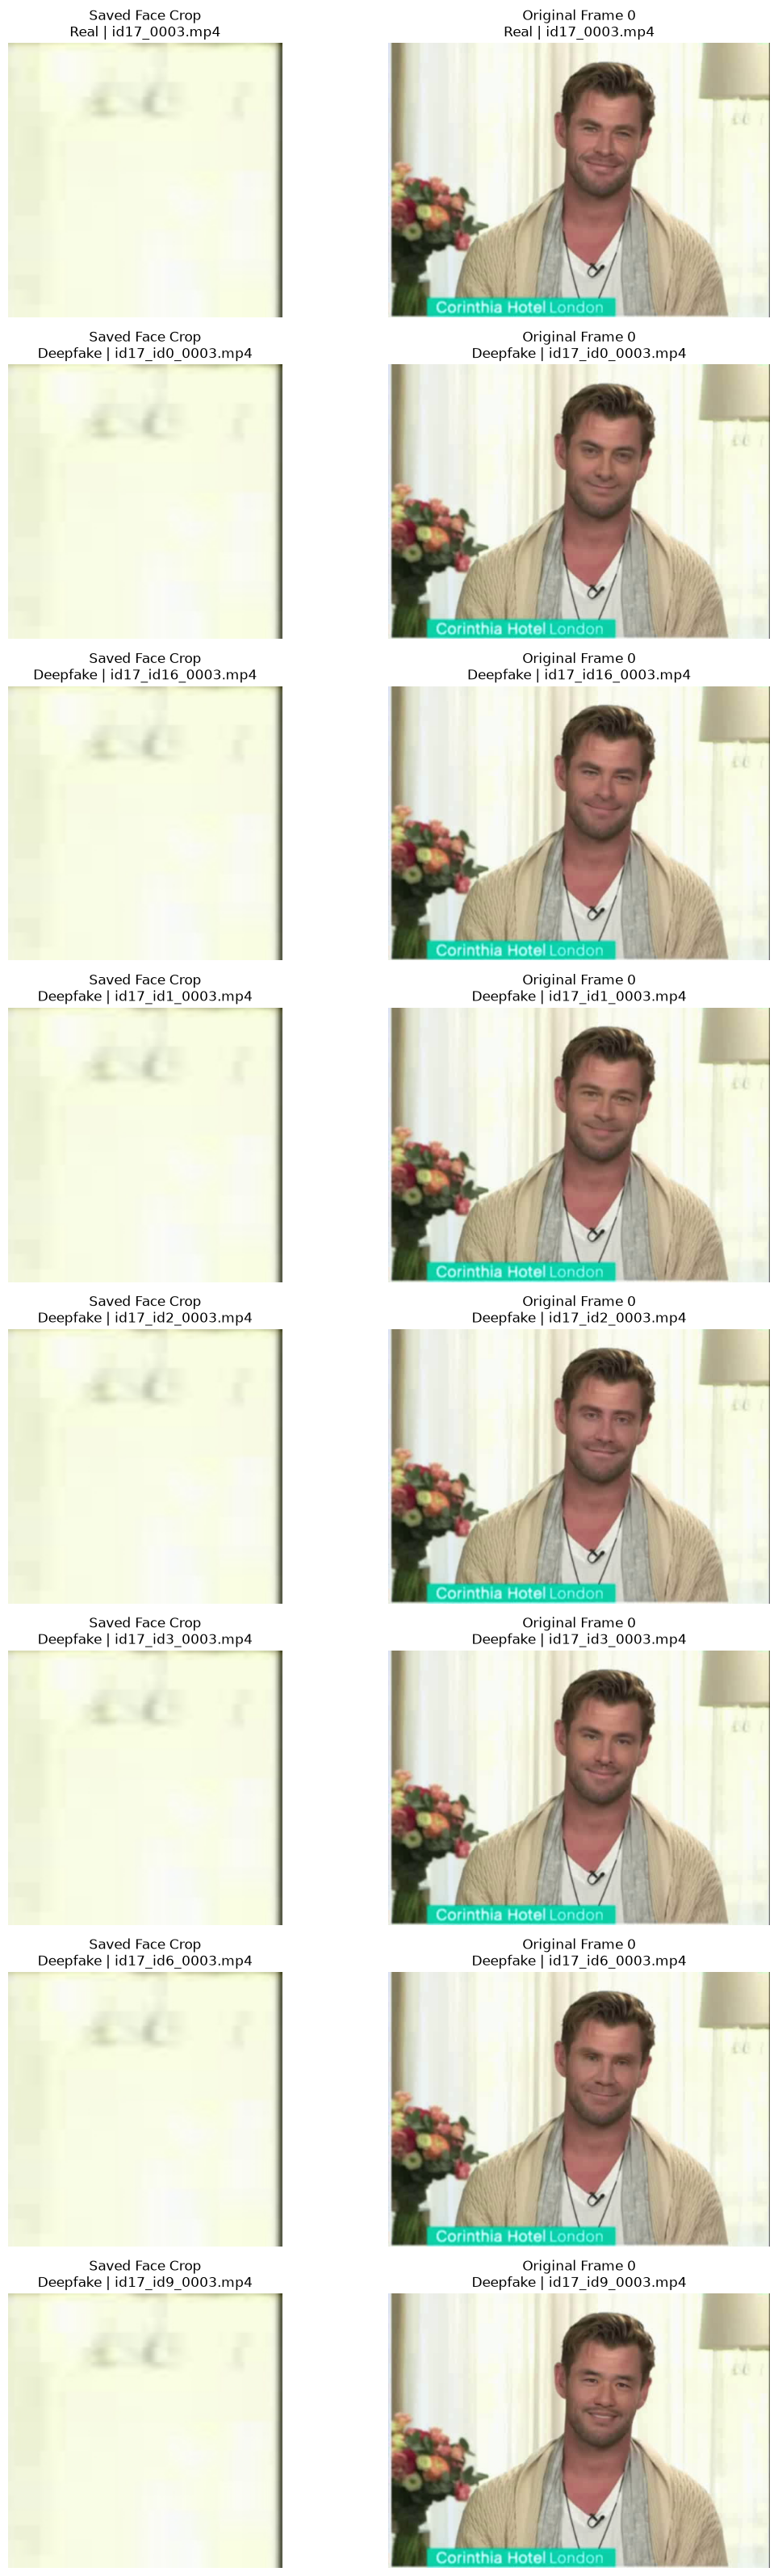


Verification image saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week14_duplicate_source_verification.png
Verification CSV saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week14_duplicate_source_verification.csv


In [26]:

# ============================================================
# WEEK 14: CROSS-LABEL DUPLICATE SOURCE IMAGE VERIFICATION
# IMPROVED VERSION
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import cv2
import pandas as pd

# 1. Check duplicate groups
if len(cross_label_groups) == 0:
    print("No cross-label duplicate groups found.")
else:

    image_hash, entries = cross_label_groups[0]

    print("=" * 60)
    print("CROSS-LABEL DUPLICATE VERIFICATION")
    print("=" * 60)

    print("Duplicate Hash:", image_hash)
    print("Number of entries:", len(entries))

    # 2. Prepare comparison figure
    fig, axes = plt.subplots(
        len(entries), 2,
        figsize=(12, 4 * len(entries)),
        squeeze=False
    )

    verification_records = []

    for i, item in enumerate(entries):

        video_name = item["video_name"]
        label = int(item["label"])
        frame_index = int(item.get("frame_index", 0))

        class_name = (
            "Real" if label == 0 else "Deepfake"
        )

        # 3. Load saved face crop
        crop_path = resolve_image_path(item["face_path"])

        if Path(crop_path).exists():
            crop = Image.open(crop_path).convert("RGB")

            axes[i, 0].imshow(crop)
            axes[i, 0].set_title(
                f"Saved Face Crop\n"
                f"{class_name} | {video_name}"
            )
        else:
            axes[i, 0].set_title("Crop not found")

        axes[i, 0].axis("off")

        # 4. Find corresponding original video
        video_match = verified_df[
            verified_df["video_name"] == video_name
        ]

        if video_match.empty:
            axes[i, 1].set_title("Original video not found")
            axes[i, 1].axis("off")
            continue

        video_path = Path(
            video_match.iloc[0]["correct_video_path"]
        )

        cap = cv2.VideoCapture(str(video_path))

        # Read corresponding frame instead of first frame
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_index
        )

        success, frame = cap.read()
        cap.release()

        if success:
            frame_rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            axes[i, 1].imshow(frame_rgb)

            axes[i, 1].set_title(
                f"Original Frame {frame_index}\n"
                f"{class_name} | {video_name}"
            )

            verification_status = "Frame loaded"

        else:
            axes[i, 1].set_title(
                f"Frame read failed: {video_name}"
            )
            verification_status = "Frame read failed"

        axes[i, 1].axis("off")

        verification_records.append({
            "duplicate_hash": image_hash,
            "video_name": video_name,
            "label": label,
            "class_name": class_name,
            "frame_index": frame_index,
            "crop_path": str(crop_path),
            "video_path": str(video_path),
            "verification_status": verification_status
        })

    plt.tight_layout()

    # 5. Save visualization
    output_path = (
        RESULTS_DIR /
        "week14_duplicate_source_verification.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    # 6. Save verification metadata
    verification_df = pd.DataFrame(
        verification_records
    )

    csv_path = (
        RESULTS_DIR /
        "week14_duplicate_source_verification.csv"
    )

    verification_df.to_csv(
        csv_path,
        index=False
    )

    print("\nVerification image saved:", output_path)
    print("Verification CSV saved:", csv_path)


In [29]:

# ============================================================
# INITIALIZE HAAR CASCADE FACE DETECTOR
# ============================================================

import cv2
from pathlib import Path

CASCADE_PATH = (
    Path(cv2.data.haarcascades)
    / "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(
    str(CASCADE_PATH)
)

if face_cascade.empty():
    raise RuntimeError("Haar Cascade failed to load!")

print("Face Cascade Loaded Successfully!")
print("Cascade Path:", CASCADE_PATH)


Face Cascade Loaded Successfully!
Cascade Path: c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Lib\site-packages\cv2\data\haarcascade_frontalface_default.xml
